In [1]:
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
import glob
from PIL import Image
import matplotlib.image as mpimg

In [3]:
O_img = [{'O': cv2.imread(file)} for file in glob.glob("DATASET/TRAIN/O/*.jpg")]

In [4]:
O_img = [{'O': cv2.cvtColor(O_img[i]['O'], cv2.COLOR_BGR2RGB)} for i in range(len(O_img))]

In [5]:
R_img = [{'R': cv2.imread(file)} for file in glob.glob("DATASET/TRAIN/R/*.jpg")]

In [6]:
R_img = [{'R': cv2.cvtColor(R_img[i]['R'], cv2.COLOR_BGR2RGB)} for i in range(len(R_img))]

In [7]:
train_img = O_img + R_img

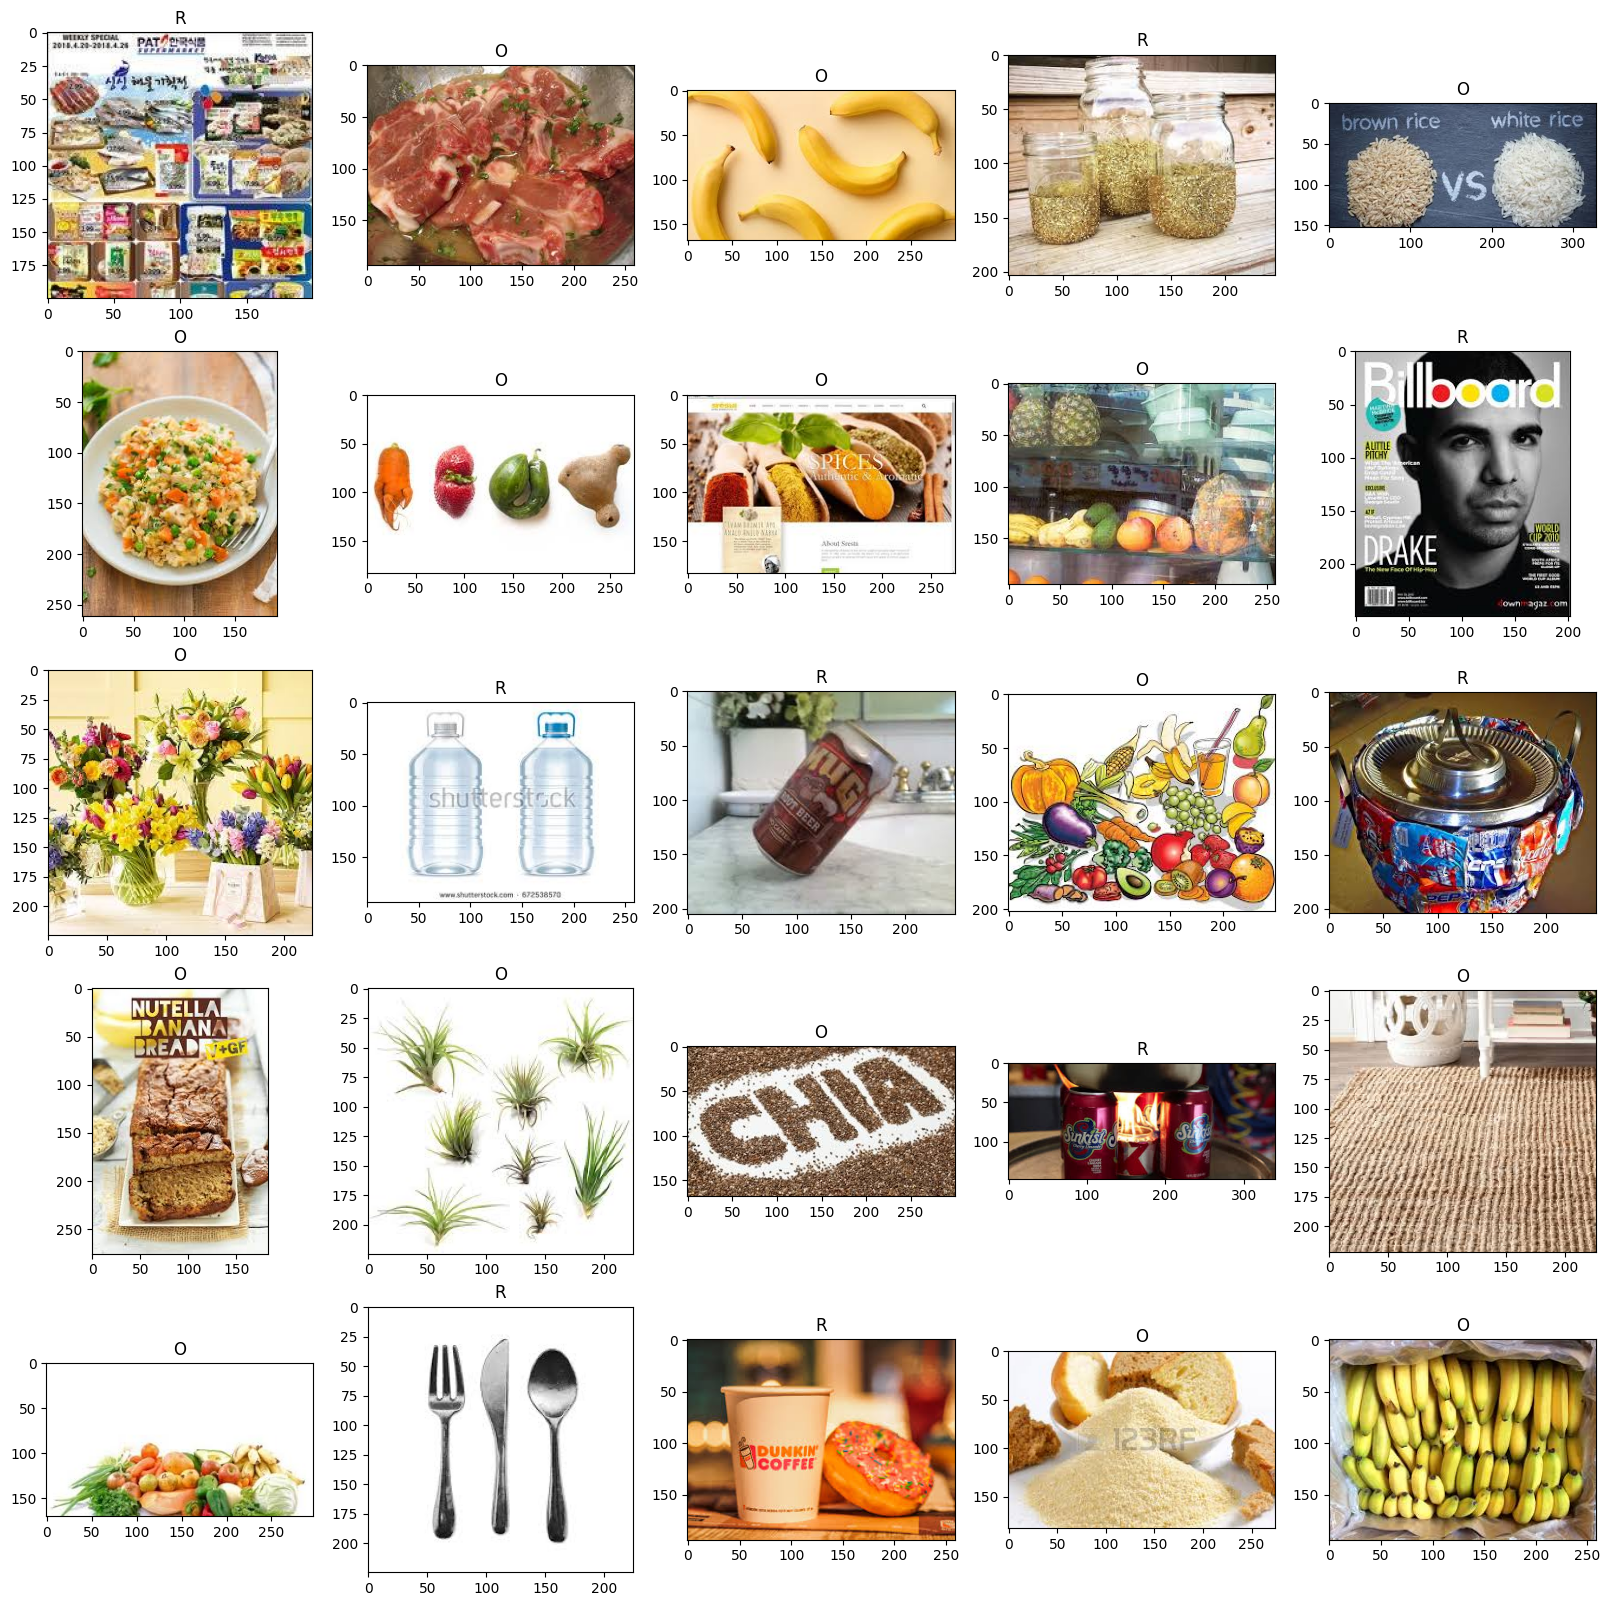

In [8]:
import random
fig = plt.figure(figsize=(20,20))
for i, img in enumerate(random.choices(train_img, k=25), 1):
    #print(i, img)
    for key, val in img.items():
        #print(key)
        if key == 'R':
            ax = fig.add_subplot(5,5,i)
            #print(val)
            plt.title('R')
            ax.imshow(val)
        elif key == 'O':
            ax = fig.add_subplot(5,5,i)
            #print(l)
            plt.title('O')
            ax.imshow(val)
        #mpplot.show()

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

2025-03-04 19:47:15.311123: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-03-04 19:47:15.330286: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-04 19:47:15.543186: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-04 19:47:15.733010: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1741114035.892066    4759 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1741114035.93

In [10]:
image_gen = ImageDataGenerator(rotation_range=30, 
                               width_shift_range=0.1, 
                               height_shift_range=0.1, 
                               rescale=1/255, 
                               shear_range=0.2, 
                               zoom_range=0.2, 
                               horizontal_flip=True, 
                               fill_mode='nearest' 
                              )

In [11]:
#Width, Height, Channels
image_shape = (150, 150, 3)

In [12]:
from keras.models import Sequential
from keras.layers import Activation, Dropout, Flatten, Dense, Conv2D, MaxPooling2D, BatchNormalization
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

In [13]:
model = Sequential()
model.add(Conv2D(32,kernel_size=(3, 3),kernel_initializer='he_normal',activation='relu',input_shape=image_shape,name = 'conv0'))
model.add(Conv2D(32, kernel_size=(3, 3),activation='relu', name = 'conv1'))
model.add(BatchNormalization(name='bn0'))
model.add(MaxPooling2D(pool_size=(2, 2),name = 'maxpool0'))
model.add(Dropout(0.2,name='dropout0'))

model.add(Conv2D(64, kernel_size=(3, 3), activation='relu',name = 'conv2'))
model.add(Conv2D(64, kernel_size=(3, 3),activation='relu', name = 'conv3'))
model.add(BatchNormalization(name='bn1'))
model.add(MaxPooling2D(pool_size=(2, 2),name = 'maxpool1'))
model.add(Dropout(0.2,name='dropout1'))

model.add(Conv2D(128, kernel_size=(3, 3), activation='relu',name = 'conv4'))
model.add(Conv2D(128, kernel_size=(3, 3),activation='relu',name = 'conv5'))
model.add(BatchNormalization(name='bn2'))
model.add(MaxPooling2D(pool_size=(2, 2),name = 'maxpool2'))
model.add(Dropout(0.3,name='dropout2'))

model.add(Conv2D(256, kernel_size=(3, 3), activation='relu',name = 'conv6'))
model.add(Conv2D(256, kernel_size=(3, 3),activation='relu',name = 'conv7'))
model.add(BatchNormalization(name='bn3'))
model.add(MaxPooling2D(pool_size=(2, 2),name = 'maxpool3'))
model.add(Dropout(0.3,name='dropout3'))

model.add(Flatten(name='fc'))
model.add(Dense(512, activation='relu',name = 'Dense0'))
model.add(Dense(256, activation='relu',name = 'Dense1'))
model.add(Dense(128, activation='relu',name = 'Dense2'))
model.add(Dropout(0.3,name='dropout4'))
model.add(Dense(2, activation='softmax',name = 'Dense3'))

model.compile(loss="sparse_categorical_crossentropy",optimizer='adam',metrics=['accuracy'])

/home/jayran/.local/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-03-04 19:47:22.250569: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv0 (Conv2D)                  │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 146, 146, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn0 (BatchNormalization)        │ (None, 146, 146, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool0 (MaxPooling2D)         │ (None, 73, 73, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout0 (Dropout)              │ (None, 73, 73, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 71, 71, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 69, 69, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 69, 69, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool1 (MaxPooling2D)         │ (None, 34, 34, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 34, 34, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 30, 30, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 30, 30, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool2 (MaxPooling2D)         │ (None, 15, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 15, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv6 (Conv2D)                  │ (None, 13, 13, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv7 (Conv2D)                  │ (None, 11, 11, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 11, 11, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool3 (MaxPooling2D)         │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout3 (Dropout)              │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc (Flatten)                    │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense0 (Dense)                  │ (None, 512)            │     3,277,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense1 (Dense)                  │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense2 (Dense)                  │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout4 (Dropout)              │ (None, 128)            │             

 Total params: 4,615,970 (17.61 MB)

 Trainable params: 4,615,010 (17.60 MB)

 Non-trainable params: 960 (3.75 KB)

training

In [15]:
batch_size = 16

train_image_gen = image_gen.flow_from_directory('DATASET/TRAIN',
                                               target_size=image_shape[:2],
                                               batch_size=batch_size,
                                               class_mode='binary')

Found 22564 images belonging to 2 classes.


In [16]:
batch_size = 16

test_image_gen = image_gen.flow_from_directory('DATASET/TEST',
                                               target_size=image_shape[:2],
                                               batch_size=batch_size,
                                               class_mode='binary')

Found 2513 images belonging to 2 classes.


In [17]:
train_image_gen.class_indices

{'O': 0, 'R': 1}

In [18]:
import warnings
warnings.filterwarnings('ignore')

In [19]:
results = model.fit(train_image_gen,
                              epochs=80,
                              steps_per_epoch=150,
                              validation_data=test_image_gen,
                              validation_steps=12)

Epoch 1/80
150/150 ━━━━━━━━━━━━━━━━━━━━ 76s 479ms/step - accuracy: 0.6670 - loss: 1.0246 - val_accuracy: 0.5781 - val_loss: 0.6418
Epoch 2/80
150/150 ━━━━━━━━━━━━━━━━━━━━ 73s 484ms/step - accuracy: 0.7696 - loss: 0.5200 - val_accuracy: 0.8125 - val_loss: 0.4973
Epoch 3/80
150/150 ━━━━━━━━━━━━━━━━━━━━ 76s 505ms/step - accuracy: 0.7856 - loss: 0.4997 - val_accuracy: 0.8698 - val_loss: 0.3960
Epoch 4/80
150/150 ━━━━━━━━━━━━━━━━━━━━ 85s 564ms/step - accuracy: 0.7818 - loss: 0.4830 - val_accuracy: 0.8385 - val_loss: 0.4203
Epoch 5/80
150/150 ━━━━━━━━━━━━━━━━━━━━ 72s 481ms/step - accuracy: 0.7880 - loss: 0.4796 - val_accuracy: 0.8802 - val_loss: 0.3008
Epoch 6/80
150/150 ━━━━━━━━━━━━━━━━━━━━ 83s 553ms/step - accuracy: 0.7962 - loss: 0.4681 - val_accuracy: 0.6667 - val_loss: 0.9528
Epoch 7/80
150/150 ━━━━━━━━━━━━━━━━━━━━ 82s 545ms/step - accuracy: 0.7920 - loss: 0.4680 - val_accuracy: 0.6354 - val_loss: 0.5812
Epoch 8/80
150/150 ━━━━━━━━━━━━━━━━━━━━ 88s 587ms/step - accuracy: 0.8036 - loss: 0

In [20]:
model.save('wsVGGver.h5')

In [21]:
results.history['accuracy']

[0.6962500214576721,
 0.76541668176651,
 0.784166693687439,
 0.7887499928474426,
 0.7904166579246521,
 0.804857611656189,
 0.7883333563804626,
 0.8087499737739563,
 0.8025000095367432,
 0.8268442749977112,
 0.7945833206176758,
 0.8183333277702332,
 0.8058333396911621,
 0.8204166889190674,
 0.8241666555404663,
 0.8266666531562805,
 0.82791668176651,
 0.8283082246780396,
 0.8083333373069763,
 0.8299180269241333,
 0.8179166913032532,
 0.8120833039283752,
 0.8166666626930237,
 0.8237500190734863,
 0.8308207988739014,
 0.8387500047683716,
 0.8254166841506958,
 0.8383333086967468,
 0.8374999761581421,
 0.8145492076873779,
 0.8287269473075867,
 0.8370833396911621,
 0.8391666412353516,
 0.8462499976158142,
 0.8383333086967468,
 0.8441666960716248,
 0.8399999737739563,
 0.8349999785423279,
 0.8450000286102295,
 0.8668032884597778,
 0.8558333516120911,
 0.8525000214576721,
 0.8566666841506958,
 0.8500000238418579,
 0.85916668176651,
 0.8545833230018616,
 0.8529166579246521,
 0.8491666913032532,


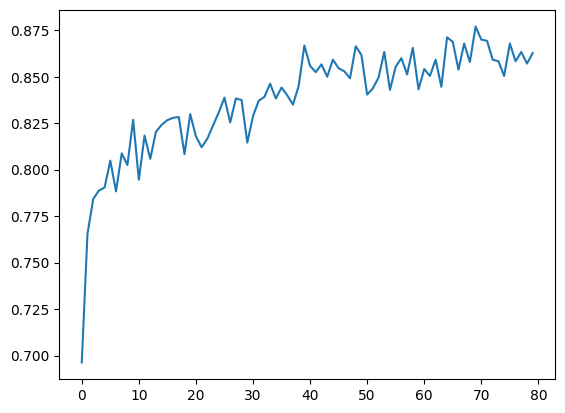

In [22]:
plt.plot(results.history['accuracy'])

testing

In [23]:
import numpy as np
from keras.preprocessing import image

R_file = 'DATASET/TEST/R/R_10148.jpg'

R_test = image.load_img(R_file, target_size=(150, 150))

R_test = image.img_to_array(R_test)

R_test = np.expand_dims(R_test, axis=0)

R_test = R_test/255

In [24]:
prediction_prob = model.predict(R_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step


In [25]:
print(f'R Probability {prediction_prob}  ')

R Probability [[0.42891568 0.5710843 ]]  
